In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import os

from concurrent.futures import ProcessPoolExecutor

np.random.seed(42)

# Jumlah titik simulasi
N = 20000

data = pd.DataFrame({
    "x": np.random.uniform(0, 10, N),
    "y": np.random.uniform(0, 10, N),
    "rainfall_mm": np.random.uniform(10, 200, N),
    "river_distance_km": np.random.uniform(0.1, 5, N),
    "soil_infiltration": np.random.uniform(5, 80, N)
})

display(data.head())

print("Jumlah titik simulasi:", len(data))
print("Jumlah CPU yang tersedia:", os.cpu_count())

,x,y,rainfall_mm,river_distance_km,soil_infiltration
0,3.745401,7.299983,66.793288,3.733620,66.362334
1,9.507143,1.845120,28.015377,4.417399,15.895232
2,7.319939,3.466397,34.008253,2.369581,75.984785
3,5.986585,6.632806,44.327514,1.516976,68.241809
4,1.560186,4.820893,48.694134,1.662348,73.913997


Jumlah titik simulasi: 20000
Jumlah CPU yang tersedia: 2


In [3]:
def calculate_risk(row):
    rainfall = row["rainfall_mm"]
    distance = row["river_distance_km"]
    infiltration = row["soil_infiltration"]

    # Normalisasi nilai ke rentang 0-1
    rain_score = min(rainfall / 200, 1)
    river_score = 1 - min(distance / 5, 1)
    absorption_score = 1 - min(infiltration / 80, 1)

    risk = (
        0.50 * rain_score
        + 0.30 * river_score
        + 0.20 * absorption_score
    )

    return risk

In [4]:
start_serial = time.perf_counter()

serial_scores = [
    calculate_risk(row)
    for row in data.to_dict("records")
]

serial_time = time.perf_counter() - start_serial

data["risk_serial"] = serial_scores

print(f"Waktu komputasi serial: {serial_time:.4f} detik")
display(data.head())

Waktu komputasi serial: 0.0535 detik


,x,y,rainfall_mm,river_distance_km,soil_infiltration,risk_serial
0,3.745401,7.299983,66.793288,3.733620,66.362334,0.277060
1,9.507143,1.845120,28.015377,4.417399,15.895232,0.265256
2,7.319939,3.466397,34.008253,2.369581,75.984785,0.252884
3,5.986585,6.632806,44.327514,1.516976,68.241809,0.349196
4,1.560186,4.820893,48.694134,1.662348,73.913997,0.337209


In [5]:
def calculate_chunk(rows):
    return [calculate_risk(row) for row in rows]


records = data.drop(columns=["risk_serial"]).to_dict("records")

# Membagi data menjadi beberapa bagian
num_workers = min(os.cpu_count() or 2, 4)
chunks = np.array_split(
    np.arange(len(records)),
    num_workers
)

record_chunks = [
    [records[i] for i in chunk]
    for chunk in chunks
    if len(chunk) > 0
]

start_parallel = time.perf_counter()

with ProcessPoolExecutor(max_workers=num_workers) as executor:
    chunk_results = list(executor.map(calculate_chunk, record_chunks))

parallel_scores = [
    score
    for chunk in chunk_results
    for score in chunk
]

parallel_time = time.perf_counter() - start_parallel

data["risk_parallel"] = parallel_scores

print("Jumlah proses:", num_workers)
print(f"Waktu komputasi paralel: {parallel_time:.4f} detik")
print(
    "Hasil serial dan paralel sama:",
    np.allclose(serial_scores, parallel_scores)
)

Jumlah proses: 2
Waktu komputasi paralel: 0.0760 detik
Hasil serial dan paralel sama: True


In [6]:
def risk_category(score):
    if score >= 0.70:
        return "Tinggi"
    elif score >= 0.40:
        return "Sedang"
    else:
        return "Rendah"


data["risk_category"] = data["risk_parallel"].apply(
    risk_category
)

summary = (
    data["risk_category"]
    .value_counts()
    .reindex(["Tinggi", "Sedang", "Rendah"], fill_value=0)
    .rename_axis("Kategori")
    .reset_index(name="Jumlah Titik")
)

display(summary)

print("Persentase setiap kategori:")
display(
    (summary.assign(
        Persentase=lambda df: (
            df["Jumlah Titik"] / len(data) * 100
        ).round(2)
    ))
)

,Kategori,Jumlah Titik
0,Tinggi,2730
1,Sedang,11401
2,Rendah,5869


Persentase setiap kategori:


,Kategori,Jumlah Titik,Persentase
0,Tinggi,2730,13.65
1,Sedang,11401,57.00
2,Rendah,5869,29.34


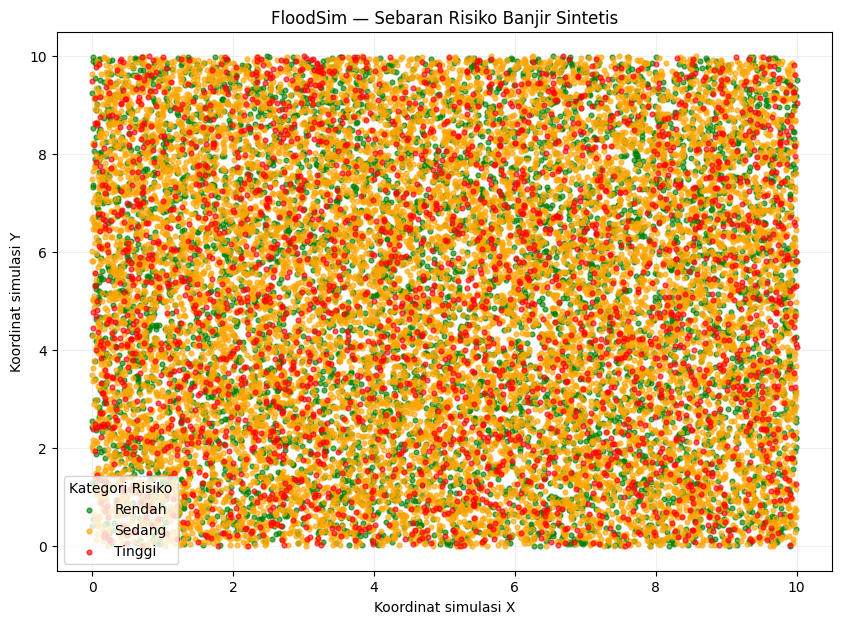

In [7]:
colors = {
    "Rendah": "green",
    "Sedang": "orange",
    "Tinggi": "red"
}

plt.figure(figsize=(10, 7))

for category, color in colors.items():
    subset = data[data["risk_category"] == category]

    plt.scatter(
        subset["x"],
        subset["y"],
        c=color,
        label=category,
        alpha=0.65,
        s=12
    )

plt.title("FloodSim — Sebaran Risiko Banjir Sintetis")
plt.xlabel("Koordinat simulasi X")
plt.ylabel("Koordinat simulasi Y")
plt.legend(title="Kategori Risiko")
plt.grid(alpha=0.2)
plt.show()

In [8]:
comparison = pd.DataFrame({
    "Metode": ["Serial", "Paralel"],
    "Waktu (detik)": [serial_time, parallel_time]
})

display(comparison)

if parallel_time > 0:
    speedup = serial_time / parallel_time
    print(f"Speedup paralel: {speedup:.2f}x")

    if speedup > 1:
        print("Pada pengujian ini, paralel lebih cepat.")
    elif speedup < 1:
        print("Pada pengujian ini, serial lebih cepat.")
    else:
        print("Kedua metode memiliki waktu yang hampir sama.")

,Metode,Waktu (detik)
0,Serial,0.053550
1,Paralel,0.075988


Speedup paralel: 0.70x
Pada pengujian ini, serial lebih cepat.


In [9]:
data.to_csv("floodsim_results.csv", index=False)
comparison.to_csv("benchmark_results.csv", index=False)

print("File berhasil dibuat:")
print("- floodsim_results.csv")
print("- benchmark_results.csv")

File berhasil dibuat:
- floodsim_results.csv
- benchmark_results.csv


In [10]:
from google.colab import files

files.download("floodsim_results.csv")
files.download("benchmark_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>